In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("churn data.csv")

print(df.shape)

(7043, 21)


In [2]:
df.shape

(7043, 21)

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
# Check missing values in each column

df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [6]:
# Check blank or whitespace values

(df.astype(str).apply(lambda col: col.str.strip().eq('')).sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [7]:
# Check duplicate rows

df.duplicated().sum()

np.int64(0)

In [8]:
df['customerID'].duplicated().sum()

np.int64(0)

In [9]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [10]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [11]:
# Convert TotalCharges into numeric format

df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

In [12]:
df['TotalCharges'].dtype

dtype('float64')

In [13]:
df['TotalCharges'].isnull().sum()

np.int64(11)

In [14]:
df[df['TotalCharges'].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [15]:
df[df['TotalCharges'].isnull()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [16]:
missing_data = df[
    df['TotalCharges'].isnull()
]

missing_data[
    ['customerID', 'tenure',
     'MonthlyCharges', 'TotalCharges']
]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [17]:
missing_data['tenure'].value_counts()

tenure
0    11
Name: count, dtype: int64

In [19]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [20]:
print("Missing values:",
      df['TotalCharges'].isnull().sum())

print("Data type:",
      df['TotalCharges'].dtype)

Missing values: 0
Data type: float64


In [21]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [22]:
# Check monthly charges distribution

df['MonthlyCharges'].describe()

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64

In [23]:
Q1 = df['MonthlyCharges'].quantile(0.25)
Q3 = df['MonthlyCharges'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)

Q1: 35.5
Q3: 89.85
IQR: 54.349999999999994
Lower Bound: -46.02499999999999
Upper Bound: 171.375


In [24]:
outliers = df[
    (df['MonthlyCharges'] < lower) |
    (df['MonthlyCharges'] > upper)
]

print("Total outliers:", len(outliers))

Total outliers: 0


In [25]:
df['Contract'].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [26]:
df['PaymentMethod'].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [27]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [28]:
contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn']
)

print(contract_churn)

Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48


In [29]:
contract_churn_rate = (
    df.groupby('Contract')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .round(2)
)

print(contract_churn_rate)

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


In [30]:
support_churn = pd.crosstab(
    df['TechSupport'],
    df['Churn']
)

print(support_churn)

Churn                  No   Yes
TechSupport                    
No                   2027  1446
No internet service  1413   113
Yes                  1734   310


In [31]:
support_churn_rate = (
    df.groupby('TechSupport')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .round(2)
)

print(support_churn_rate)

TechSupport
No                     41.64
No internet service     7.40
Yes                    15.17
Name: Churn, dtype: float64


In [32]:
pd.crosstab(
    [df['Contract'], df['TechSupport']],
    df['Churn'],
    normalize='index'
).mul(100).round(2)

Churn                                  No    Yes
Contract       TechSupport                      
Month-to-month No                   49.63  50.37
               No internet service  81.11  18.89
               Yes                  69.30  30.70
One year       No                   85.28  14.72
               No internet service  97.53   2.47
               Yes                  86.41  13.59
Two year       No                   94.07   5.93
               No internet service  99.22   0.78
               Yes                  96.47   3.53

In [33]:
pd.crosstab(
    [df['Contract'], df['TechSupport']],
    df['Churn']
)

Churn                                 No   Yes
Contract       TechSupport                    
Month-to-month No                   1330  1350
               No internet service   425    99
               Yes                   465   206
One year       No                    475    82
               No internet service   355     9
               Yes                   477    75
Two year       No                    222    14
               No internet service   633     5
               Yes                   792    29

In [34]:
contract_support_analysis = pd.crosstab(
    [df['Contract'], df['TechSupport']],
    df['Churn']
)

print(contract_support_analysis)

Churn                                 No   Yes
Contract       TechSupport                    
Month-to-month No                   1330  1350
               No internet service   425    99
               Yes                   465   206
One year       No                    475    82
               No internet service   355     9
               Yes                   477    75
Two year       No                    222    14
               No internet service   633     5
               Yes                   792    29


In [35]:
contract_support_analysis['Churn_Rate'] = (
    contract_support_analysis['Yes'] /
    contract_support_analysis.sum(axis=1)
) * 100

contract_support_analysis.round(2)

Churn                                 No   Yes  Churn_Rate
Contract       TechSupport                                
Month-to-month No                   1330  1350       50.37
               No internet service   425    99       18.89
               Yes                   465   206       30.70
One year       No                    475    82       14.72
               No internet service   355     9        2.47
               Yes                   477    75       13.59
Two year       No                    222    14        5.93
               No internet service   633     5        0.78
               Yes                   792    29        3.53

In [36]:
df.to_csv(
    "cleaned_customer_churn.csv",
    index=False
)

In [37]:
contract_support_analysis = pd.crosstab(
    [df['Contract'], df['TechSupport']],
    df['Churn']
)

contract_support_analysis

Churn                                 No   Yes
Contract       TechSupport                    
Month-to-month No                   1330  1350
               No internet service   425    99
               Yes                   465   206
One year       No                    475    82
               No internet service   355     9
               Yes                   477    75
Two year       No                    222    14
               No internet service   633     5
               Yes                   792    29

In [38]:
contract_support_analysis['Churn_Rate'] = (
    contract_support_analysis['Yes'] /
    (contract_support_analysis['Yes'] +
     contract_support_analysis['No'])
) * 100

contract_support_analysis.round(2)

Churn                                 No   Yes  Churn_Rate
Contract       TechSupport                                
Month-to-month No                   1330  1350       50.37
               No internet service   425    99       18.89
               Yes                   465   206       30.70
One year       No                    475    82       14.72
               No internet service   355     9        2.47
               Yes                   477    75       13.59
Two year       No                    222    14        5.93
               No internet service   633     5        0.78
               Yes                   792    29        3.53

In [43]:
df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        '0-12 Months',
        '13-24 Months',
        '25-48 Months',
        '49-72 Months'
    ]
)

In [40]:
tenure_analysis = (
    df.groupby('TenureGroup', observed=False)
    .agg(
        Total_Customers=('customerID', 'count'),
        Churned_Customers=(
            'Churn',
            lambda x: (x == 'Yes').sum()
        )
    )
)

tenure_analysis['Churn_Rate'] = (
    tenure_analysis['Churned_Customers'] /
    tenure_analysis['Total_Customers'] * 100
).round(2)

tenure_analysis

,Total_Customers,Churned_Customers,Churn_Rate
TenureGroup,,,
0-12 Months,2186,1037,47.44
13-24 Months,1024,294,28.71
25-48 Months,1594,325,20.39
49-72 Months,2239,213,9.51


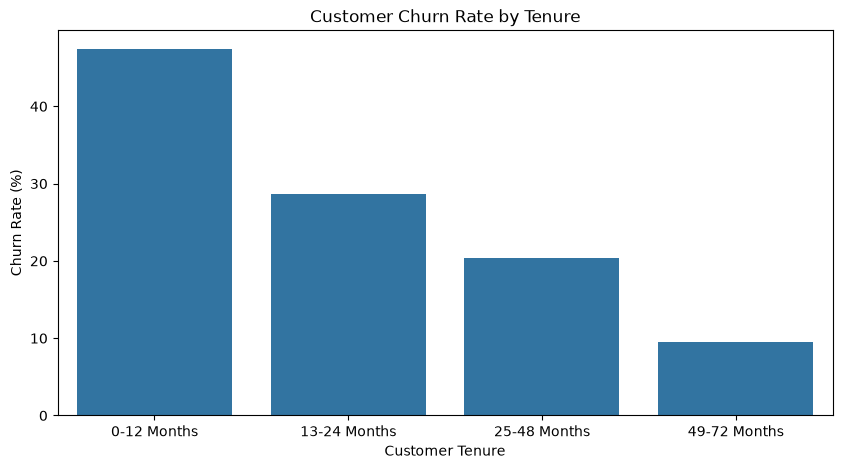

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=tenure_analysis.reset_index(),
    x='TenureGroup',
    y='Churn_Rate'
)

plt.title('Customer Churn Rate by Tenure')
plt.xlabel('Customer Tenure')
plt.ylabel('Churn Rate (%)')

plt.show()

In [44]:
df['PaymentMethod'].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [45]:
payment_analysis = pd.crosstab(
    df['PaymentMethod'],
    df['Churn']
)

payment_analysis

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


In [46]:
payment_analysis['Churn_Rate'] = (
    payment_analysis['Yes'] /
    (payment_analysis['Yes'] + payment_analysis['No'])
) * 100

payment_analysis = payment_analysis.round(2)

payment_analysis

Churn,No,Yes,Churn_Rate
PaymentMethod,,,
Bank transfer (automatic),1286,258,16.71
Credit card (automatic),1290,232,15.24
Electronic check,1294,1071,45.29
Mailed check,1304,308,19.11


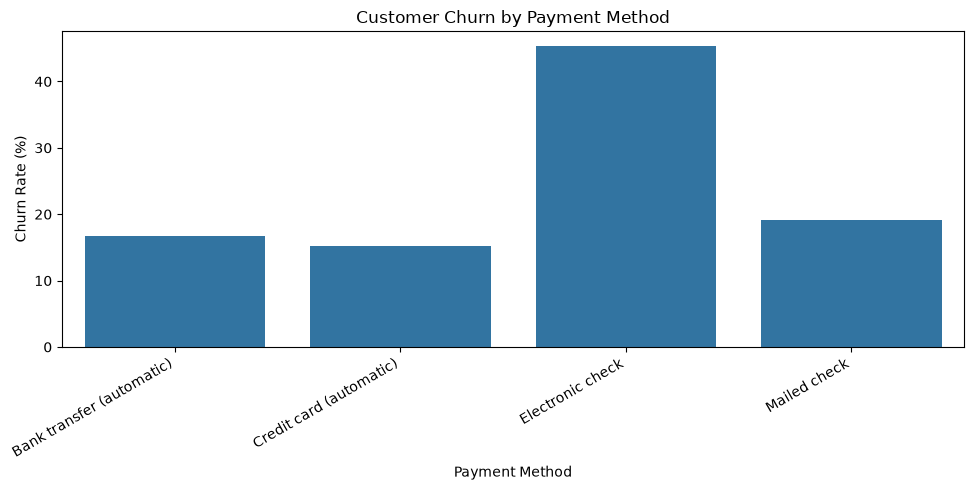

In [47]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=payment_analysis.index,
    y=payment_analysis['Churn_Rate']
)

plt.title('Customer Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.show()

In [48]:
df['InternetService'].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [49]:
internet_analysis = pd.crosstab(
    df['InternetService'],
    df['Churn']
)

internet_analysis

Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


In [50]:
internet_analysis['Churn_Rate'] = (
    internet_analysis['Yes'] /
    (internet_analysis['Yes'] + internet_analysis['No'])
) * 100

internet_analysis = internet_analysis.round(2)

internet_analysis

Churn,No,Yes,Churn_Rate
InternetService,,,
DSL,1962,459,18.96
Fiber optic,1799,1297,41.89
No,1413,113,7.40


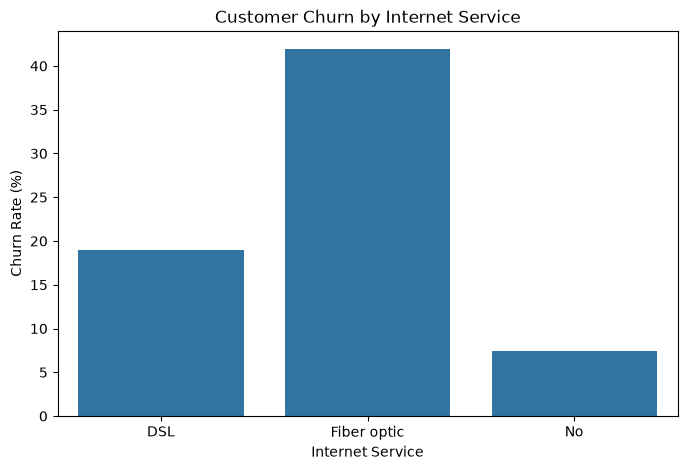

In [51]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=internet_analysis.index,
    y=internet_analysis['Churn_Rate']
)

plt.title('Customer Churn by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Churn Rate (%)')

plt.show()

In [52]:
service_columns = [
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

service_results = []

for col in service_columns:

    churn_rate = (
        df.groupby(col)['Churn']
        .apply(lambda x: (x == 'Yes').mean() * 100)
    )

    for category, rate in churn_rate.items():

        service_results.append({
            'Service': col,
            'Category': category,
            'Churn_Rate': round(rate, 2)
        })

service_analysis = pd.DataFrame(service_results)

service_analysis

,Service,Category,Churn_Rate
0,OnlineSecurity,No,41.77
1,OnlineSecurity,No internet service,7.40
2,OnlineSecurity,Yes,14.61
3,OnlineBackup,No,39.93
4,OnlineBackup,No internet service,7.40
5,OnlineBackup,Yes,21.53
6,DeviceProtection,No,39.13
7,DeviceProtection,No internet service,7.40
8,DeviceProtection,Yes,22.50
9,TechSupport,No,41.64


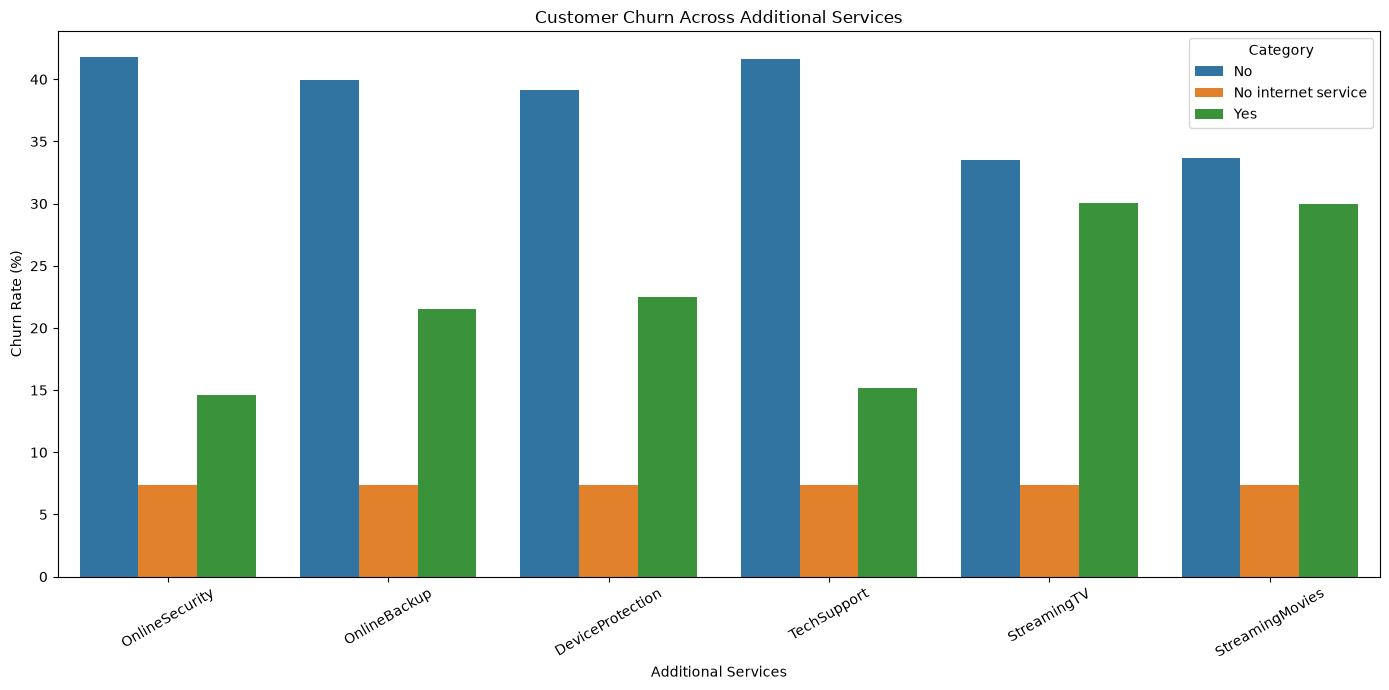

In [53]:
plt.figure(figsize=(14, 7))

sns.barplot(
    data=service_analysis,
    x='Service',
    y='Churn_Rate',
    hue='Category'
)

plt.title('Customer Churn Across Additional Services')
plt.xlabel('Additional Services')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

In [54]:

# Create tenure groups

bins = [0, 12, 24, 48, 72]
labels = ['0-12 Months', '13-24 Months', '25-48 Months', '49-72 Months']

df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Calculate churn count and churn rate
tenure_churn = df.groupby('TenureGroup', observed=False).agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=('Churn', lambda x: (x == 'Yes').sum())
)

tenure_churn['Churn_Rate'] = (
    tenure_churn['Churned_Customers'] /
    tenure_churn['Total_Customers'] * 100
).round(2)

tenure_churn


,Total_Customers,Churned_Customers,Churn_Rate
TenureGroup,,,
0-12 Months,2186,1037,47.44
13-24 Months,1024,294,28.71
25-48 Months,1594,325,20.39
49-72 Months,2239,213,9.51


In [57]:

gender_churn = df.groupby('gender').agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=('Churn', lambda x: (x == 'Yes').sum())
)

gender_churn['Churn_Rate'] = (
    gender_churn['Churned_Customers'] /
    gender_churn['Total_Customers'] * 100
).round(2)

gender_churn


,Total_Customers,Churned_Customers,Churn_Rate
gender,,,
Female,3488,939,26.92
Male,3555,930,26.16


In [58]:

senior_churn = df.groupby('SeniorCitizen').agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=('Churn', lambda x: (x == 'Yes').sum())
)

senior_churn['Churn_Rate'] = (
    senior_churn['Churned_Customers'] /
    senior_churn['Total_Customers'] * 100
).round(2)

senior_churn.index = ['Non-Senior Citizen', 'Senior Citizen']

senior_churn


,Total_Customers,Churned_Customers,Churn_Rate
Non-Senior Citizen,5901,1393,23.61
Senior Citizen,1142,476,41.68


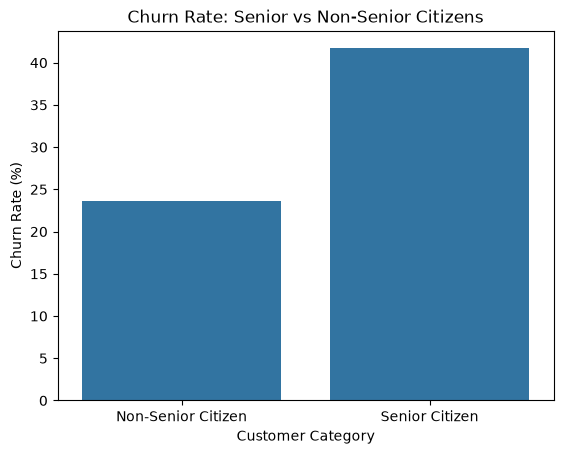

In [59]:

sns.barplot(
    x=senior_churn.index,
    y=senior_churn['Churn_Rate']
)

plt.title('Churn Rate: Senior vs Non-Senior Citizens')
plt.xlabel('Customer Category')
plt.ylabel('Churn Rate (%)')
plt.show()


In [60]:

contract_payment_churn = df.groupby(
    ['Contract', 'PaymentMethod']
).agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=('Churn', lambda x: (x == 'Yes').sum())
)

contract_payment_churn['Churn_Rate'] = (
    contract_payment_churn['Churned_Customers'] /
    contract_payment_churn['Total_Customers'] * 100
).round(2)

contract_payment_churn = contract_payment_churn.sort_values(
    by='Churn_Rate',
    ascending=False
)

contract_payment_churn


Total_Customers  Churned_Customers  \
Contract       PaymentMethod                                                   
Month-to-month Electronic check                      1850                994   
               Bank transfer (automatic)              589                201   
               Credit card (automatic)                543                178   
               Mailed check                           893                282   
One year       Electronic check                       347                 64   
               Credit card (automatic)                398                 41   
               Bank transfer (automatic)              391                 38   
Two year       Electronic check                       168                 13   
One year       Mailed check                           337                 23   
Two year       Bank transfer (automatic)              564                 19   
               Credit card (automatic)                581                 13   
               Mailed check                           382                  3   

                                          Churn_Rate  
Contract       PaymentMethod                          
Month-to-month Electronic check                53.73  
               Bank transfer (automatic)       34.13  
               Credit card (automatic)         32.78  
               Mailed check                    31.58  
One year       Electronic check                18.44  
               Credit card (automatic)         10.30  
               Bank transfer (automatic)        9.72  
Two year       Electronic check                 7.74  
One year       Mailed check                     6.82  
Two year       Bank transfer (automatic)        3.37  
               Credit card (automatic)          2.24  
               Mailed check                     0.79

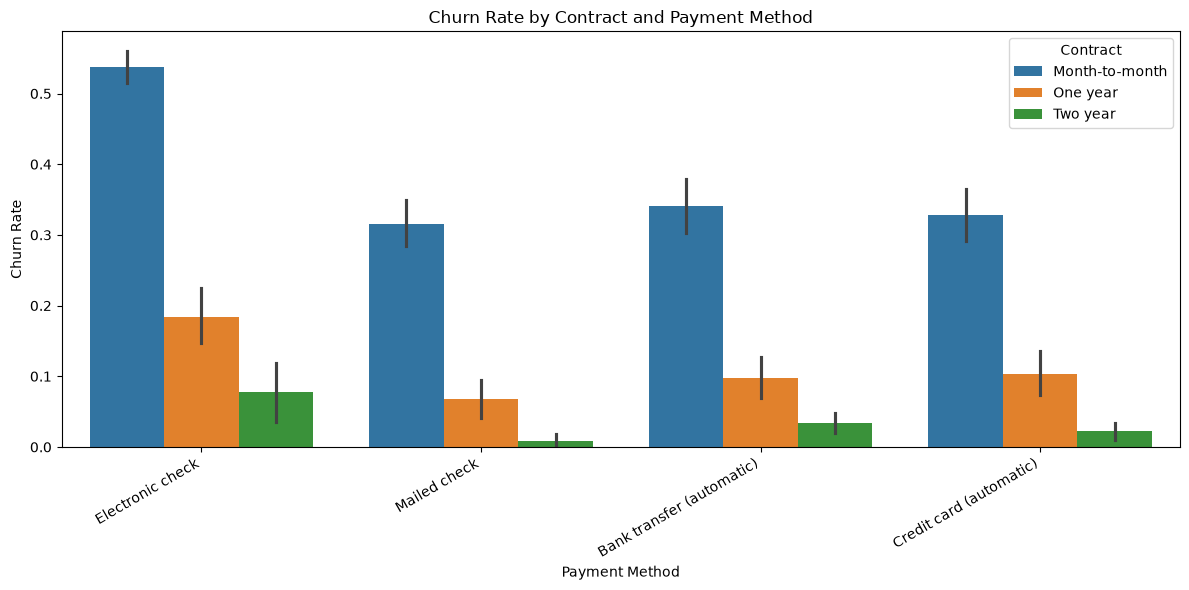

In [61]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x='PaymentMethod',
    y=df['Churn'].eq('Yes').astype(int),
    hue='Contract',
    estimator='mean'
)

plt.title('Churn Rate by Contract and Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Churn Rate')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


In [62]:

# Calculate estimated historical revenue per customer

df['EstimatedRevenue'] = (
    df['MonthlyCharges'] * df['tenure']
)

df[['customerID', 'tenure', 'MonthlyCharges',
    'EstimatedRevenue', 'Churn']].head()


,customerID,tenure,MonthlyCharges,EstimatedRevenue,Churn
0,7590-VHVEG,1,29.85,29.85,No
1,5575-GNVDE,34,56.95,1936.30,No
2,3668-QPYBK,2,53.85,107.70,Yes
3,7795-CFOCW,45,42.30,1903.50,No
4,9237-HQITU,2,70.70,141.40,Yes


In [63]:

revenue_churn = df.groupby('Churn').agg(
    Total_Customers=('customerID', 'count'),
    Average_Tenure=('tenure', 'mean'),
    Average_Monthly_Charges=('MonthlyCharges', 'mean'),
    Total_Estimated_Revenue=('EstimatedRevenue', 'sum'),
    Average_Revenue_Per_Customer=('EstimatedRevenue', 'mean')
).round(2)

revenue_churn


,Total_Customers,Average_Tenure,Average_Monthly_Charges,Total_Estimated_Revenue,Average_Revenue_Per_Customer
Churn,,,,,
No,5174,37.57,61.27,13192514.55,2549.77
Yes,1869,17.98,74.44,2862576.90,1531.61


In [64]:

churned_customers = df[df['Churn'] == 'Yes']

total_revenue_exposure = churned_customers['EstimatedRevenue'].sum()

monthly_revenue_at_risk = churned_customers['MonthlyCharges'].sum()

print("Historical Revenue from Churned Customers:",
      round(total_revenue_exposure, 2))

print("Monthly Recurring Revenue at Risk:",
      round(monthly_revenue_at_risk, 2))


Historical Revenue from Churned Customers: 2862576.9
Monthly Recurring Revenue at Risk: 139130.85


In [65]:
## Business Insights

1. **Contract Type:** Month-to-month contract customers show a higher churn rate compared to one-year and two-year contract customers.
2. **Technical Support:** Customers without technical support have a higher churn rate than customers with technical support.
3. **Customer Tenure:** Customer tenure helps identify whether newer customers are more likely to leave.
4. **Payment Method:** Payment method analysis helps identify customer groups with different churn rates.
5. **Revenue Impact:** Churned customers generated approximately ₹28.63 lakh in estimated historical revenue and represented ₹1.39 lakh in monthly recurring revenue at the time of churn.

SyntaxError: invalid character '₹' (U+20B9) (254341116.py, line 7)

In [66]:
## Business Recommendations

1. **Improve Customer Retention:** Focus on month-to-month contract customers by offering suitable long-term contract benefits.
2. **Improve Technical Support:** Review customer complaints, unresolved tickets and support response times.
3. **Early Customer Engagement:** Identify customers in their initial months and proactively understand their concerns.
4. **Payment Experience:** Investigate whether payment-related difficulties contribute to customer cancellations.
5. **Revenue Protection:** Prioritize retention efforts for high-value customers who show signs of churn risk.

SyntaxError: invalid syntax (452617638.py, line 3)

In [ ]:
## Final Conclusion

The exploratory data analysis identified differences in customer churn across contract types, technical support, payment methods, tenure and additional services.

The analysis also highlighted the financial impact of customer churn. Churned customers accounted for approximately ₹28.63 lakh in estimated historical revenue and ₹1.39 lakh in monthly recurring revenue at the time of churn.

The findings can help the business identify high-risk customer segments, investigate cancellation reasons and develop better customer retention strategies.

In [67]:
df.to_csv(
    "cleaned_customer_churn.csv",
    index=False
)